In [ ]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(GEOquery)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


# Sample inflamed / disease distribution

In [72]:
md_5p_new  <- read_csv("data//predict_5p_metadata_20260819.csv")

Rows: 1382 Columns: 56
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (50): sample, data_folder, diagnosis, subgroup_primary, subgroup_second...
dbl   (4): days, severity_score, weighted_severity_score, age
date  (2): dob, collection_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [80]:
md_5p_new

sample,data_folder,diagnosis,subgroup_primary,subgroup_secondary,subgroup_tertiary,Rome_coarse,Rome_classification,antitnf_response,participant_id,⋯,descending_inflammation,transverse_inflammation,ascending_inflammation,micro_duo_inflammation,micro_ile_inflammation,micro_col_inflammation,colon_site,experiment_protocol_version,Paris,antitnf_repeat_old
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
001-002_T0_COL_LP_5p_N1,1193580_1_1_2,FGID,FDR,NA,NA,C,C3,NM,001-002,⋯,N,N,N,N,N,Y,Transverse,GI_v1,NA,NM
001-002_T0_DUO_LP_5p_N1,1193579_1_1_2,FGID,FDR,NA,NA,C,C3,NM,001-002,⋯,N,N,N,N,N,Y,Transverse,GI_v1,NA,NM
001-004_T0_COL_LP_5p_N1,1193488_1_1_2,CD,ileal,nonstricturing_nonpenetrating,none,NM,NM,FR,001-004,⋯,N,N,N,N,Y,N,Left,GI_v1,L1B1,NM
001-004_T0_DUO_LP_5p_N1,1193487_1_1_2,CD,ileal,nonstricturing_nonpenetrating,none,NM,NM,FR,001-004,⋯,N,N,N,N,Y,N,Left,GI_v1,L1B1,NM
001-006_T0_COL_LP_5p_N1,1193581_1_1_2,UC,extensive,never severe,none,NM,NM,NOA,001-006,⋯,Y,Y,N,N,N,Y,Left,GI_v1,E3S0,NM
001-009_T0_BLD_CD3_5p_N1,1740262_1_1_1,FGID,CVS,NA,NA,H1,H1a,NM,001-009,⋯,N,N,N,Y,N,Y,Left,Blood_v1,NA,NM
001-009_T0_BLD_CD3_5p_N1,1740262_1_1_1,FGID,CVS,NA,NA,H1,H1a,NM,001-009,⋯,N,N,N,Y,N,Y,Left,Blood_v1,NA,NM
001-009_T0_COL_LP_5p_N1,1193611_1_1_1,FGID,CVS,NA,NA,H1,H1a,NM,001-009,⋯,N,N,N,Y,N,Y,Left,GI_v1,NA,NM
001-009_T0_COL_LP_5p_N1,1193611_1_1_2,FGID,CVS,NA,NA,H1,H1a,NM,001-009,⋯,N,N,N,Y,N,Y,Left,GI_v1,NA,NM


In [73]:
md_5p_gut  <- read_csv("../241201_VN_PREDICT2/data/metadata//250121_Gut_5p_metadata.csv")

New names:
• `` -> `...1`
Rows: 346456 Columns: 129
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (75): ...1, orig.ident, bc, data_folder, data_folder2, sample, diagnosis...
dbl (46): nCount_RNA, nFeature_RNA, age, days, scrublet_doublet_scores, n_ou...
lgl  (8): outliers, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [74]:
md_5p_gut$participant_id  %>% table  %>% length

[1] 99

In [75]:
md_5p_new$participant_id  %>% table  %>% length

[1] 116

In [76]:
pt_3p  <- gsub(c('p009',
'p011',
'p014',
'p016',
'p017',
'p018',
'p019',
'p022',
'p023',
'p024',
'p026',
'p027',
'p028',
'p030',
'p031',
'p032',
'p033',
'p034',
'p035',
'p037',
'p041',
'p042',
'p043',
'p044',
'p048',
'p049',
'p050'), pattern = "p", replacement = "001-")

In [77]:
pt_5p  <- md_5p_gut$participant_id  %>% unique() 
pt_5p  <- pt_5p[which(!(pt_5p %in% pt_3p))]

In [78]:
pt_5p

[1] "001-015" "001-036" "001-038" "001-040" "001-045" "001-047" "001-051"
 [8] "001-052" "001-053" "001-055" "001-057" "001-058" "001-059" "001-062"
[15] "001-063" "001-064" "001-066" "001-068" "001-069" "001-070" "001-071"
[22] "001-074" "001-077" "001-078" "001-079" "001-082" "001-085" "001-086"
[29] "001-089" "001-090" "001-091" "001-092" "001-094" "001-101" "001-103"
[36] "003-001" "003-002" "003-004" "003-005" "003-006" "003-007" "003-008"
[43] "003-010" "003-011" "003-012" "003-016" "003-017" "003-026" "003-027"
[50] "003-030" "003-034" "003-036" "003-039" "003-042" "003-043" "003-046"
[57] "003-051" "003-059" "003-066" "003-072" "003-074" "003-077" "HE-009" 
[64] "HE-011"  "HE-012"  "HE-014"  "HE-023"  "HE-024"  "HE-025"  "HE-026" 
[71] "HE-027"  "HE-028"  "003-024"

In [79]:
pt_3p

[1] "001-009" "001-011" "001-014" "001-016" "001-017" "001-018" "001-019"
 [8] "001-022" "001-023" "001-024" "001-026" "001-027" "001-028" "001-030"
[15] "001-031" "001-032" "001-033" "001-034" "001-035" "001-037" "001-041"
[22] "001-042" "001-043" "001-044" "001-048" "001-049" "001-050"

In [80]:
cohort_5p  <- pt_5p
cohort_3p  <- pt_3p

In [89]:
colnames(md_5p_new)

[1] "sample"                      "data_folder"                
 [3] "diagnosis"                   "subgroup_primary"           
 [5] "subgroup_secondary"          "subgroup_tertiary"          
 [7] "Rome_coarse"                 "Rome_classification"        
 [9] "antitnf_response"            "participant_id"             
[11] "timepoint"                   "site"                       
[13] "tissue"                      "layer"                      
[15] "prime"                       "version_10x"                
[17] "data_type"                   "seq_run"                    
[19] "collection_purpose"          "days"                       
[21] "antitnf"                     "antitnf_repeat"             
[23] "sample_inflamed"             "score_type"                 
[25] "severity_score"              "weighted_severity_score"    
[27] "severity_score_date"         "severity_score_range"       
[29] "weighted_score_range"        "internal_flag"              
[31] "y2passed"                    "diagnosis_R_change"         
[33] "y2response"                  "micro_rc_inflammation"      
[35] "micro_lc_inflammation"       "dob"                        
[37] "age"                         "sex"                        
[39] "collection_date"             "duo_inflammation"           
[41] "ile_inflammation"            "race"                       
[43] "ethnicity"                   "col_inflammation"           
[45] "perianal_inflammation"       "recto_sigmoid_inflammation" 
[47] "descending_inflammation"     "transverse_inflammation"    
[49] "ascending_inflammation"      "micro_duo_inflammation"     
[51] "micro_ile_inflammation"      "micro_col_inflammation"     
[53] "colon_site"                  "experiment_protocol_version"
[55] "Paris"                       "antitnf_repeat_old"

In [81]:
md_5p_new  %>% 
dplyr::filter(timepoint == "T0" & diagnosis == "CD")  %>% 
dplyr::filter(participant_id %in% cohort_5p)  %>% 
group_by(subgroup_primary, participant_id)  %>% 
tally()  %>% 
ungroup  %>% 
group_by(subgroup_primary)  %>% tally()

subgroup_primary,n
<chr>,<int>
Treitz_proximal ileal,2
Treitz_proximal ileocolonic,8
colonic,2
ileal,5
ileocolonic,10


In [82]:
md_5p_new <- md_5p_new %>%
  mutate(
    subgroup_collapsed = case_when(
      subgroup_primary %in% c(
        "ileal",
        "Treitz_proximal ileal"
      ) ~ "ileal",

      subgroup_primary %in% c(
        "ileocolonic",
        "Treitz_proximal ileocolonic"
      ) ~ "ileocolonic",

      subgroup_primary == "colonic" ~ "colonic",

      TRUE ~ NA_character_
    )
  )

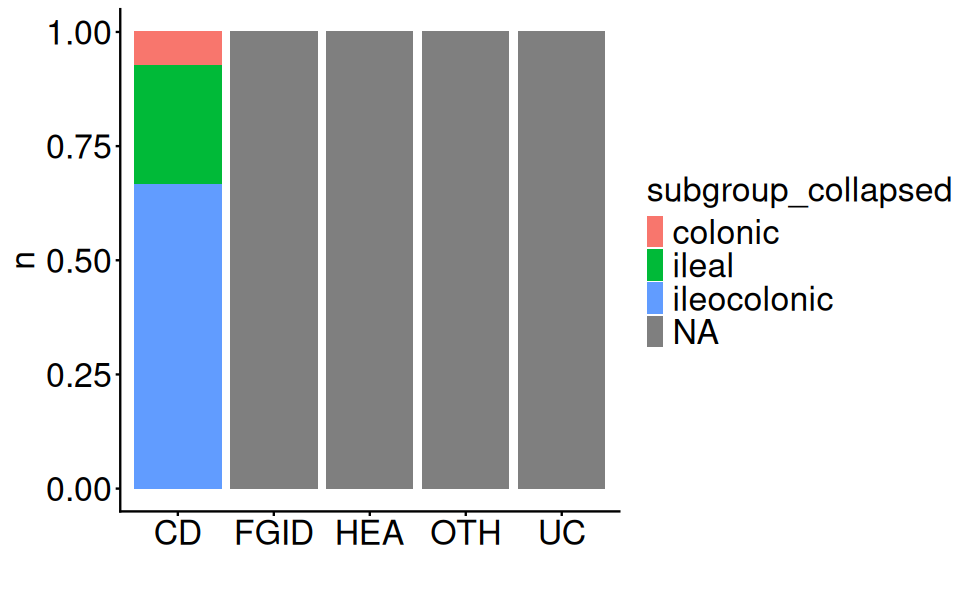

In [120]:
md_5p_new  %>% dplyr::filter(participant_id %in% pt_5p)  %>% 
mutate(diagnosis = ifelse(diagnosis == 'Unknown',"OTH",diagnosis))  %>% 
dplyr::select(participant_id, subgroup_collapsed, diagnosis)  %>% unique  %>% 
group_by(subgroup_collapsed, diagnosis)  %>%
tally()  %>% 
ggplot(aes(x = diagnosis, y = n, fill = subgroup_collapsed)) +
  geom_bar(position="fill", stat="identity") +
theme_classic() +
ggtheme() +
xlab("")

#ggsave("figures/cohort_characterization_gut/sex_identification.svg", width = 16, height = 10, units = "cm")

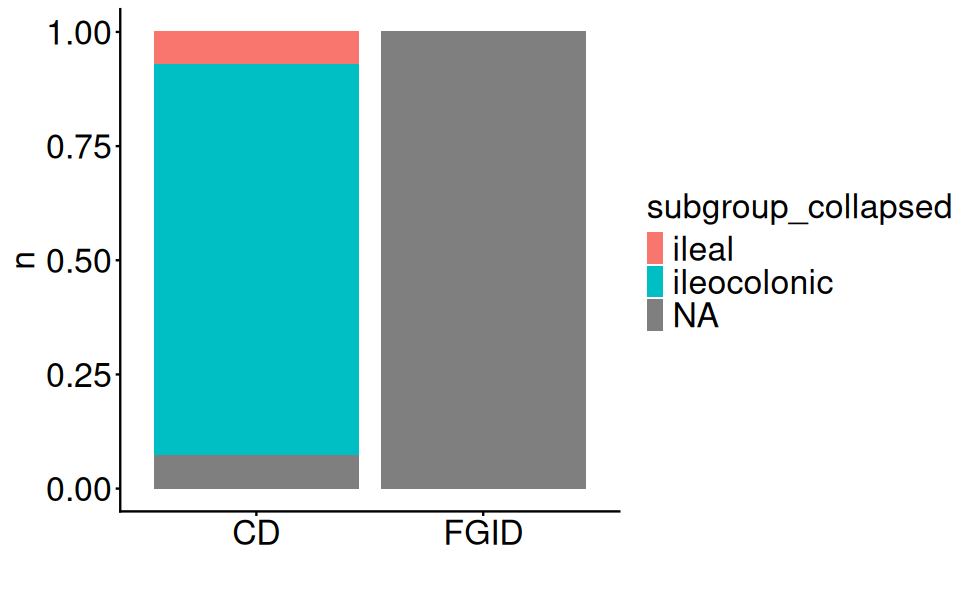

In [121]:
md_5p_new  %>% dplyr::filter(participant_id %in% pt_3p)  %>% 
mutate(diagnosis = ifelse(diagnosis == 'Unknown',"OTH",diagnosis))  %>% 
dplyr::select(participant_id, subgroup_collapsed, diagnosis)  %>% unique  %>% 
group_by(subgroup_collapsed, diagnosis)  %>%
tally()  %>% 
ggplot(aes(x = diagnosis, y = n, fill = subgroup_collapsed)) +
  geom_bar(position="fill", stat="identity") +
theme_classic() +
ggtheme() +
xlab("")

#ggsave("figures/cohort_characterization_gut/sex_identification.svg", width = 16, height = 10, units = "cm")

In [87]:
md_5p_new  <- md_5p_new  %>% mutate(cohort = case_when(participant_id %in% pt_5p ~ "5p",
                                                       participant_id %in% pt_3p ~ "3p",
                                                       TRUE ~ NA_character_))

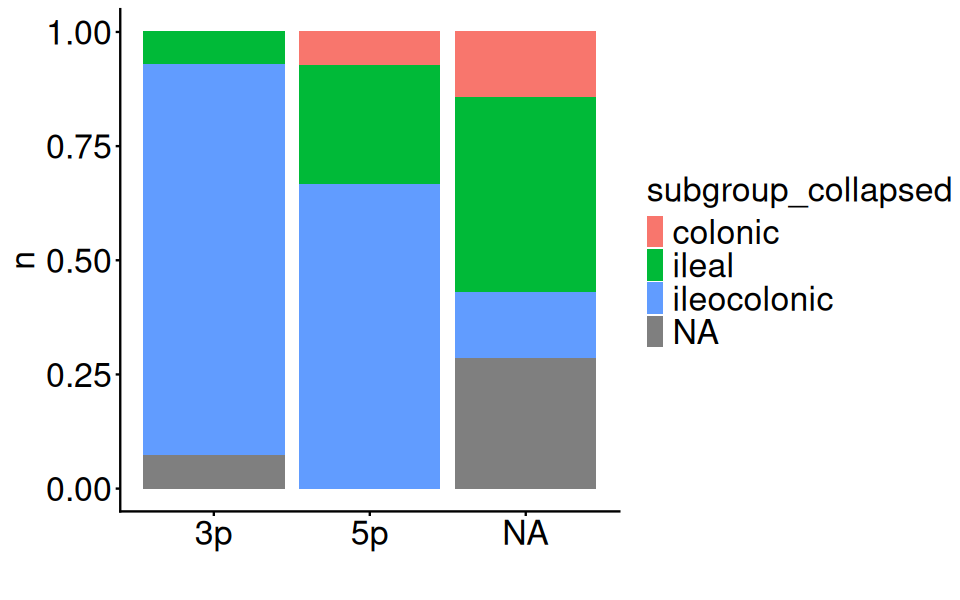

In [141]:
md_5p_new  %>% 
dplyr::filter(diagnosis == "CD" & timepoint == "T0")  %>% 
dplyr::select(participant_id, subgroup_collapsed, cohort)  %>% unique  %>% 
group_by(subgroup_collapsed, cohort)  %>%
tally()  %>% 
ggplot(aes(x = cohort, y = n, fill = subgroup_collapsed)) +
  geom_bar(position="fill", stat="identity") +
theme_classic() +
ggtheme() +
xlab("")

In [142]:
ggsave("figures/barplot_subgroup_primary.svg", width = 20, height = 10, units = "cm")

In [88]:
md_5p_new  %>% 
dplyr::filter(diagnosis == "CD" & timepoint == "T0")  %>% 
dplyr::select(participant_id, subgroup_collapsed, cohort)  %>% unique  %>% 
group_by(subgroup_collapsed, cohort)  %>%
tally()  %>% 
arrange(cohort)

subgroup_collapsed,cohort,n
<chr>,<chr>,<int>
ileal,3p,1
ileocolonic,3p,12
NA,3p,1
colonic,5p,2
ileal,5p,7
ileocolonic,5p,18
colonic,NA,1
ileal,NA,3
ileocolonic,NA,1


In [134]:
md_5p_new  %>% 
dplyr::filter(timepoint == "T0" & diagnosis == "CD")  %>% 
group_by(subgroup_secondary, participant_id, cohort)  %>% 
tally()  %>% 
ungroup  %>% 
group_by(subgroup_secondary, cohort)  %>% tally()  %>% 
arrange(cohort)

subgroup_secondary,cohort,n
<chr>,<chr>,<int>
isolated perianal,3p,1
nonstricturing_nonpenetrating,3p,13
nonstricturing_nonpenetrating,5p,22
penetrating,5p,2
stricturing,5p,3
nonstricturing_nonpenetrating,NA,6
penetrating,NA,1


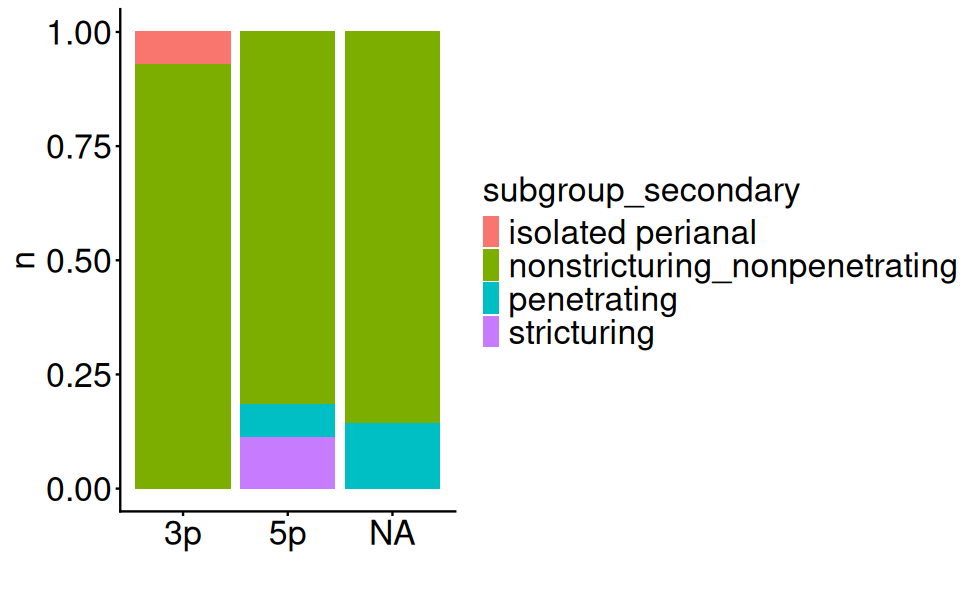

In [139]:
md_5p_new  %>% 
dplyr::filter(timepoint == "T0" & diagnosis == "CD")  %>% 
dplyr::select(participant_id, subgroup_secondary, cohort)  %>% unique  %>% 
group_by(subgroup_secondary, cohort)  %>%
tally()  %>% 
ggplot(aes(x = cohort, y = n, fill = subgroup_secondary)) +
  geom_bar(position="fill", stat="identity") +
theme_classic() +
ggtheme() +
xlab("")

In [140]:
ggsave("figures/barplot_subgroup_secondary.svg", width = 24, height = 10, units = "cm")

In [85]:
md_5p_new  %>% colnames

[1] "sample"                      "data_folder"                
 [3] "diagnosis"                   "subgroup_primary"           
 [5] "subgroup_secondary"          "subgroup_tertiary"          
 [7] "Rome_coarse"                 "Rome_classification"        
 [9] "antitnf_response"            "participant_id"             
[11] "timepoint"                   "site"                       
[13] "tissue"                      "layer"                      
[15] "prime"                       "version_10x"                
[17] "data_type"                   "seq_run"                    
[19] "collection_purpose"          "days"                       
[21] "antitnf"                     "antitnf_repeat"             
[23] "sample_inflamed"             "score_type"                 
[25] "severity_score"              "weighted_severity_score"    
[27] "severity_score_date"         "severity_score_range"       
[29] "weighted_score_range"        "internal_flag"              
[31] "y2passed"                    "diagnosis_R_change"         
[33] "y2response"                  "micro_rc_inflammation"      
[35] "micro_lc_inflammation"       "dob"                        
[37] "age"                         "sex"                        
[39] "collection_date"             "duo_inflammation"           
[41] "ile_inflammation"            "race"                       
[43] "ethnicity"                   "col_inflammation"           
[45] "perianal_inflammation"       "recto_sigmoid_inflammation" 
[47] "descending_inflammation"     "transverse_inflammation"    
[49] "ascending_inflammation"      "micro_duo_inflammation"     
[51] "micro_ile_inflammation"      "micro_col_inflammation"     
[53] "colon_site"                  "experiment_protocol_version"
[55] "Paris"                       "antitnf_repeat_old"         
[57] "subgroup_collapsed"

In [111]:
md_5p_new$duo_inflammation  <- factor(md_5p_new$duo_inflammation, levels = rev(c("Y","N","NM")))
md_5p_new$ile_inflammation  <- factor(md_5p_new$ile_inflammation, levels = rev(c("Y","N","NM")))
md_5p_new$col_inflammation  <- factor(md_5p_new$col_inflammation, levels = rev(c("Y","N","NM")))

In [90]:
md_5p_new  %>% 
dplyr::filter(timepoint == "T0" & diagnosis == "CD" & cohort %in% c("3p","5p"))  %>% 
dplyr::select(participant_id, duo_inflammation, cohort)  %>% unique  %>% 
group_by(duo_inflammation, cohort)  %>%
tally()  

duo_inflammation,cohort,n
<chr>,<chr>,<int>
N,3p,11
N,5p,17
NM,3p,1
NM,5p,1
Y,3p,2
Y,5p,9


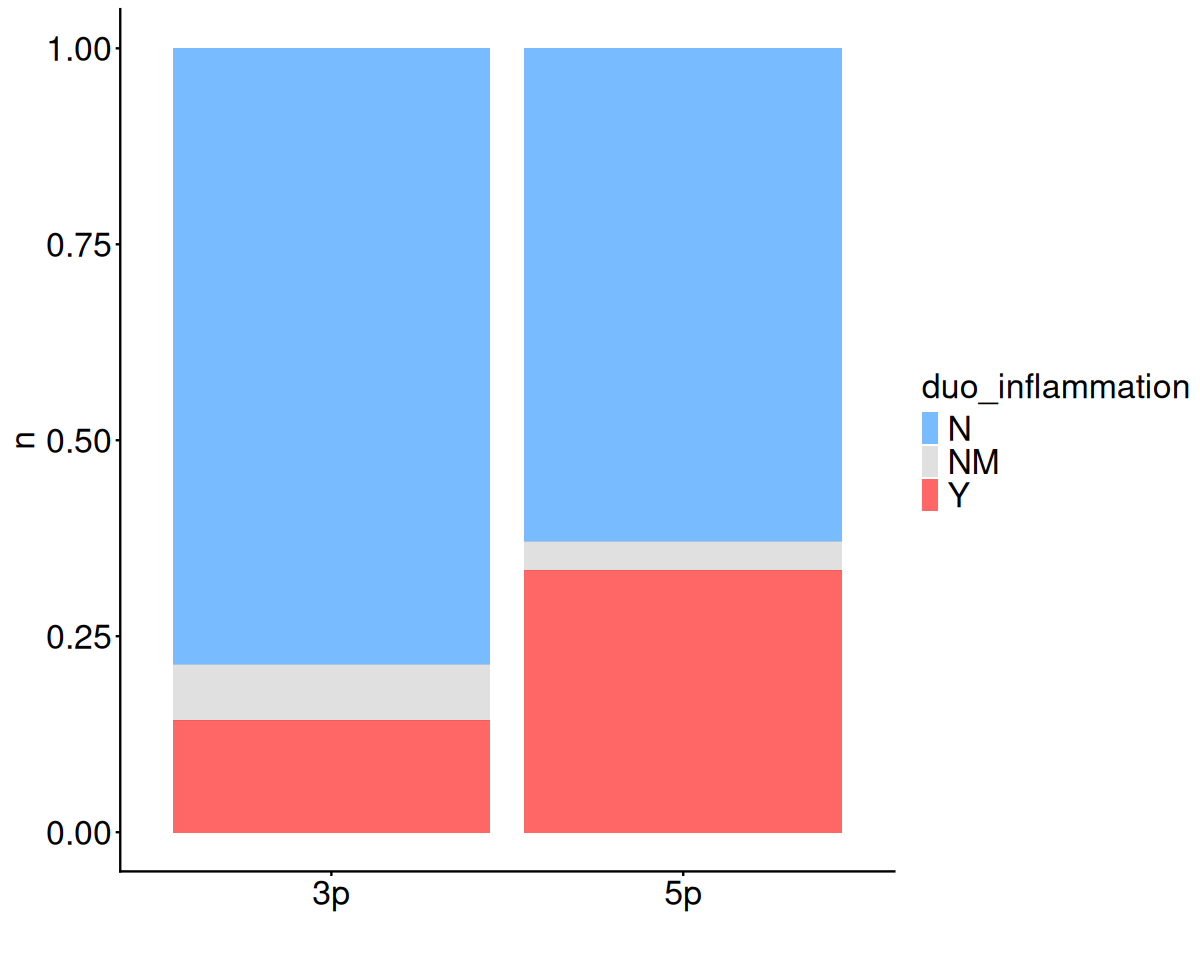

In [89]:
md_5p_new  %>% 
dplyr::filter(timepoint == "T0" & diagnosis == "CD" & cohort %in% c("3p","5p"))  %>% 
dplyr::select(participant_id, duo_inflammation, cohort)  %>% unique  %>% 
group_by(duo_inflammation, cohort)  %>%
tally()  %>% 
ggplot(aes(x = cohort, y = n, fill = duo_inflammation)) +
  geom_bar(position="fill", stat="identity", alpha = 0.6) +
scale_fill_manual(values = c("Y" = "red", "N" = "dodgerblue", "NM" = "grey80")) +
theme_classic() +
ggtheme() +
xlab("")

In [122]:
ggsave("figures/barplot_duod_inflamed.svg", width = 12, height = 10, units = "cm")

In [84]:
md_5p_new  %>% 
dplyr::filter(timepoint == "T0" & diagnosis == "CD" & cohort %in% c("3p","5p"))  %>% 
dplyr::select(participant_id, ile_inflammation, cohort)  %>% unique  %>% 
group_by(ile_inflammation, cohort)  %>%
tally()  %>% 
ggplot(aes(x = cohort, y = n, fill = ile_inflammation)) +
  geom_bar(position="fill", stat="identity", alpha = 0.6) +
scale_fill_manual(values = c("Y" = "red", "N" = "dodgerblue", "NM" = "grey80")) +
theme_classic() +
ggtheme() +
xlab("")

ERROR: Error in (function (cond) : error in evaluating the argument 'x' in selecting a method for function 'unique': [1m[22m[36mℹ[39m In argument: `timepoint == "T0" & diagnosis == "CD" & cohort %in%
  c("3p", "5p")`.
[1mCaused by error in `h()`:[22m
[33m![39m error in evaluating the argument 'x' in selecting a method for function '%in%': object 'cohort' not found


In [124]:
ggsave("figures/barplot_ile_inflamed.svg", width = 12, height = 10, units = "cm")

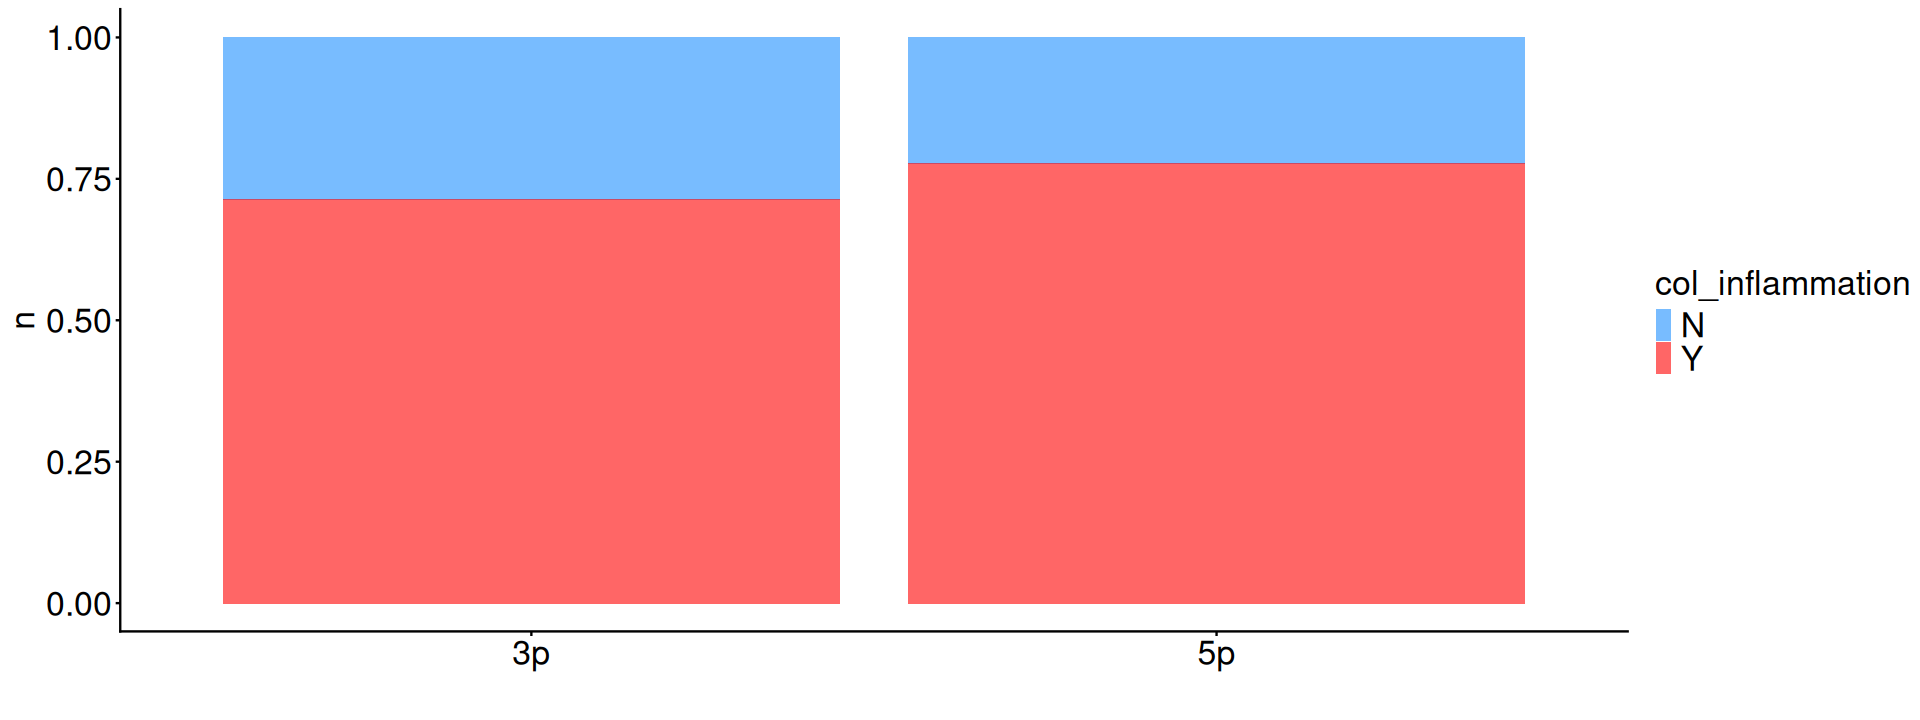

In [125]:
md_5p_new  %>% 
dplyr::filter(timepoint == "T0" & diagnosis == "CD" & cohort %in% c("3p","5p"))  %>% 
dplyr::select(participant_id, col_inflammation, cohort)  %>% unique  %>% 
group_by(col_inflammation, cohort)  %>%
tally()  %>% 
ggplot(aes(x = cohort, y = n, fill = col_inflammation)) +
  geom_bar(position="fill", stat="identity", alpha = 0.6) +
scale_fill_manual(values = c("Y" = "red", "N" = "dodgerblue", "NM" = "grey80")) +
theme_classic() +
ggtheme() +
xlab("")

In [126]:
ggsave("figures/barplot_col_inflamed.svg", width = 12, height = 10, units = "cm")